# GG4257 - Creating Sustainable Cities with Spatial Data Science
## Lab 5 Challenges
All code cells will include a brief explanation of that code line unless included in lab, in cases where I have used websites or documentation, please refer to the [x] section of the 'references' cell at the end of the notebook to view citations.
### 220016532

### Landon Evans
#### Student ID : _220016532_
#### Github : _land0nevans_
#### URL : https://github.com/land0nevans/UA-Lab2

### Challenge 1

In [1]:
#%pip install osmnx mapclassify folium overturemaps

import os
import math
import getpass
import requests
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union

In [9]:
API_KEY = getpass.getpass("Paste your ohsome API key: ")

Paste your ohsome API key:  ········


I believe it is generally not a good idea to share any type of api key, but please let me know if this will reduce marks in terms of code reproducablity. I have included screenshots in a separate pdf document and an api key can be pasted into the box above to run the code.

In [10]:
OHSOME_URL = "https://api.heigit.org/ohsome-api/v2-rc/stats/features/"
BBOX = [-3.261223,51.437745,-3.072052,51.555088]          # Cardiff, Wales

def ohsome(measure, osm_filter):
    body = {"aoi": BBOX,
            "filter": osm_filter,
            "time": {"start": "2008-01-01", "end": "2026-01-01", "interval": "P1Y"}}
    response = requests.post(OHSOME_URL + measure + ".json", json=body,
                             headers={"Authorization": API_KEY}, timeout=300)
    response.raise_for_status()               # stops here with a message if something went wrong
    result = response.json()["result"]
    years = [int(t[:4]) for t in result["timestamp"]]
    return pd.Series(result["value"], index=years)

buildings = ohsome("count", "building=* and geometry:polygon")
streets = ohsome("length", "highway in (residential, living_street) and type:way") / 1000   # metres -> km

growth = pd.DataFrame({"Buildings (count)": buildings, "Residential streets (km)": streets})
#growth

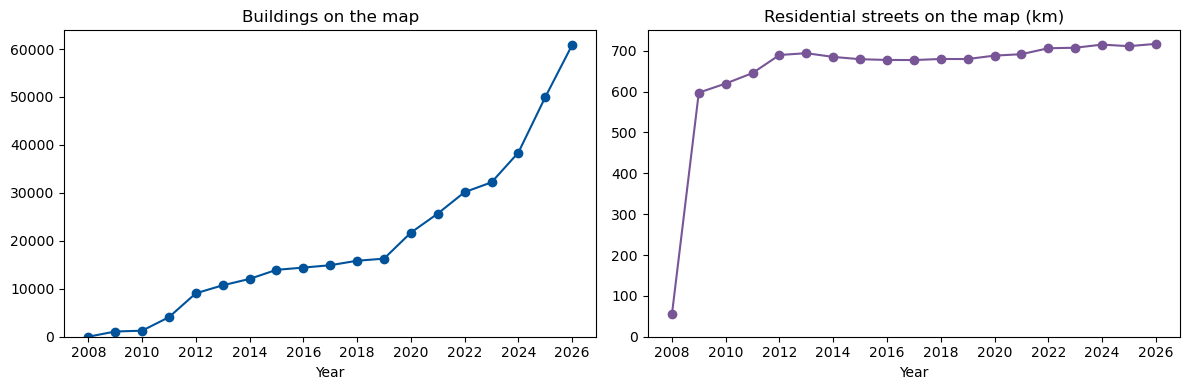

Change from 2012 to 2026 (%):
Buildings (count)           572.0
Residential streets (km)      4.0
dtype: float64


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
growth["Buildings (count)"].plot(ax=axes[0], marker="o", color="#00539B", title="Buildings on the map")
growth["Residential streets (km)"].plot(ax=axes[1], marker="o", color="#785596", title="Residential streets on the map (km)")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Year")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))   # whole years on the axis
plt.tight_layout()
plt.show()

change = (growth.loc[2026] / growth.loc[2012] - 1) * 100
print("Change from 2012 to 2026 (%):")
print(change.round(0))

Both areas have experienced growth over time but the pattern does not repeat, as Edinburgh shows a large spike in increased buildings around 2014, whereas Cardiff has a more gradual increase between 2008-2019, but then increases at a much faster rate especially after 2024. There are also more residential streets on the map in Cardiff compared to Edinburgh, at around 700km compared to 250km though the pattern is quite similar.

### Challenge 2.1

In [40]:
# 2.1 :
WALK_SPEED = 80                    # metres per minute (4.8 km/h)

G = ox.load_graphml("data/dundee_walk.graphml")
G = ox.project_graph(G, to_crs="EPSG:27700")            # British National Grid: distances in metres
nodes, edges = ox.graph_to_gdfs(G)

dundee_services = gpd.read_file("data/dundee_services.gpkg").to_crs("EPSG:27700")
print(dundee_services["service"].value_counts())

schools = dundee_services[dundee_services["service"] == "School"].copy()
print(len(nodes), "street junctions and", len(schools), "schools")

service
Food shop    104
School        28
Pharmacy      19
GP            11
Name: count, dtype: int64
12777 street junctions and 28 schools


In [41]:
schools["node"] = ox.distance.nearest_nodes(G, schools.geometry.x, schools.geometry.y)
#schools[["name", "node"]].head()

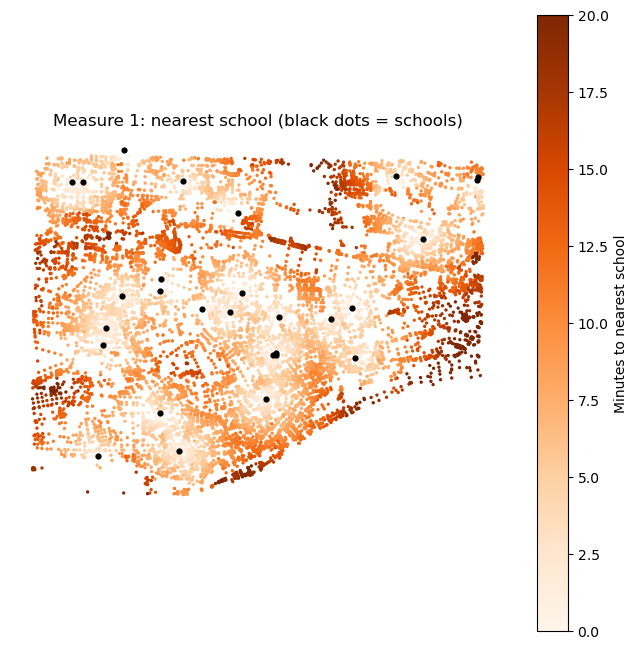

In [42]:
nearest = nx.multi_source_dijkstra_path_length(G, set(schools["node"]), weight="length")
nodes["nearest_min"] = pd.Series(nearest) / WALK_SPEED

ax = nodes.plot(column="nearest_min", cmap="Oranges", vmax=20, markersize=2, legend=True, figsize=(8, 8),
                legend_kwds={"label": "Minutes to nearest school"})
schools.plot(ax=ax, color="black", markersize=12)
ax.set_title("Measure 1: nearest school (black dots = schools)")
ax.set_axis_off()
plt.show()

### Challenge 2.2

In [50]:
# 2.2 
BETA = 0.14 # changed value for challenge

cumulative = {node: 0 for node in G.nodes}      # start every junction at zero
gravity = {node: 0.0 for node in G.nodes}

for school_node in schools["node"]:
    distances = nx.single_source_dijkstra_path_length(G, school_node, cutoff=30 * WALK_SPEED, weight="length")
    for node, metres in distances.items():
        minutes = metres / WALK_SPEED
        if minutes <= 10:
            cumulative[node] += 1
        gravity[node] += math.exp(-BETA * minutes)

nodes["cumulative"] = pd.Series(cumulative)
nodes["gravity"] = pd.Series(gravity)

#nodes[["nearest_min", "cumulative", "gravity"]].describe().round(2)

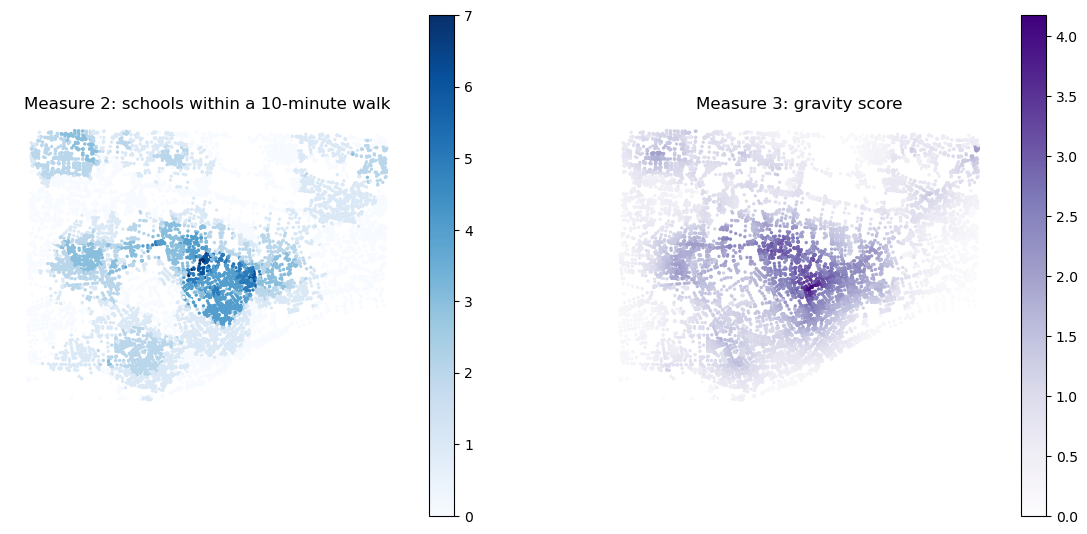

In [51]:
# here we plot the two measures side by side, using different colour maps and legends.
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
nodes.plot(ax=axes[0], column="cumulative", cmap="Blues", markersize=2, legend=True)
axes[0].set_title("Measure 2: schools within a 10-minute walk")
nodes.plot(ax=axes[1], column="gravity", cmap="Purples", markersize=2, legend=True)
axes[1].set_title("Measure 3: gravity score")
for ax in axes:
    ax.set_axis_off()
plt.show()

A higher beta would represent groups who may be unable to walk as far as it gives schools with long travel times very little weight, as they may be difficult to access for families with small children or pushchairs, elderly groups or if they need a quick school journey before work.

### Challenge 3.1

In [52]:
# first importing data using lab

import overturemaps

DUNDEE_BOX = (-3.024, 56.438, -2.926, 56.492)        # west, south, east, north

table = overturemaps.record_batch_reader("place", bbox=DUNDEE_BOX, stac=True).read_all()
places = table.to_pandas()
places["geometry"] = gpd.GeoSeries.from_wkb(places["geometry"])
places = gpd.GeoDataFrame(places, geometry="geometry", crs="EPSG:4326").to_crs("EPSG:27700")
places["name"] = places["names"].str.get("primary")      # each place can have several names; keep the main one

#print(len(places), "Overture places in Dundee")

In [53]:
#importing shops from lab
shops = dundee_services[dundee_services["service"] == "Food shop"].copy()
shops["node"] = ox.distance.nearest_nodes(G, shops.geometry.x, shops.geometry.y)
#shops[["name", "node"]].head()

In [59]:
is_food = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False)
overture_shops = places[is_food & (places["confidence"] >= 0.5)].copy()

#print(overture_shops["basic_category"].value_counts())
#print()
#print("Food shops in OpenStreetMap:", len(shops))
#print("Food shops in Overture:     ", len(overture_shops))

# 3.1
is_food = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False)
overture_shops = places[is_food & (places["confidence"] >= 0.5)].copy() # original confidence value

print(overture_shops["basic_category"].value_counts())
print()
print("Food shops in OpenStreetMap:", len(shops))
print("Food shops in Overture:     ", len(overture_shops))

In [65]:
overture_shops["node"] = ox.distance.nearest_nodes(G, overture_shops.geometry.x, overture_shops.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_shops["node"]), weight="length")
nodes["nearest_min_overture"] = pd.Series(nearest_overture) / WALK_SPEED

comparison = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture":      [nodes["nearest_min_overture"].median(), (nodes["nearest_min_overture"] <= 10).mean() * 100],
}, index=["Median minutes to nearest food shop", "% of junctions within 10 minutes"])
comparison.round(1)

,OpenStreetMap,Overture
Median minutes to nearest food shop,3.9,4.1
% of junctions within 10 minutes,87.5,87.7


In [66]:
is_food = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False)
overture_shops = places[is_food & (places["confidence"] >= 0.8)].copy() # changed to 0.8

print(overture_shops["basic_category"].value_counts())
print()
print("Food shops in OpenStreetMap:", len(shops))
print("Food shops in Overture:     ", len(overture_shops))

basic_category
convenience_store    90
Name: count, dtype: int64

Food shops in OpenStreetMap: 104
Food shops in Overture:      90


In [67]:
overture_shops["node"] = ox.distance.nearest_nodes(G, overture_shops.geometry.x, overture_shops.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_shops["node"]), weight="length")
nodes["nearest_min_overture"] = pd.Series(nearest_overture) / WALK_SPEED

comparison = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture":      [nodes["nearest_min_overture"].median(), (nodes["nearest_min_overture"] <= 10).mean() * 100],
}, index=["Median minutes to nearest food shop", "% of junctions within 10 minutes"])
comparison.round(1)

,OpenStreetMap,Overture
Median minutes to nearest food shop,3.9,4.7
% of junctions within 10 minutes,87.5,81.9


Changing the confidence threshold shows a difference in 31 shops (121 to 90), and the median minutes to nearest food shop increases to 4.7 minutes from 4.1, and there are 5.6% less junctions within a 10 minute walk. The gap widens further when applying a higher confidence threshold.

### Challenge 3.2

In [68]:
pharmacy = dundee_services[dundee_services["service"] == "Pharmacy"].copy()

In [69]:
pharmacy["node"] = ox.distance.nearest_nodes(G, pharmacy.geometry.x, pharmacy.geometry.y)
#pharmacy[["name", "node"]].head()

In [72]:
#3.2
is_pharmacy= places["basic_category"].str.contains("pharmacy|drug", na=False)
overture_pharmacy = places[is_pharmacy & (places["confidence"] >= 0.5)].copy()

print("Pharmacies in OpenStreetMap:", len(pharmacy))
print("Pharmacies in Overture:     ", len(overture_pharmacy))

Pharmacies in OpenStreetMap: 19
Pharmacies in Overture:      34


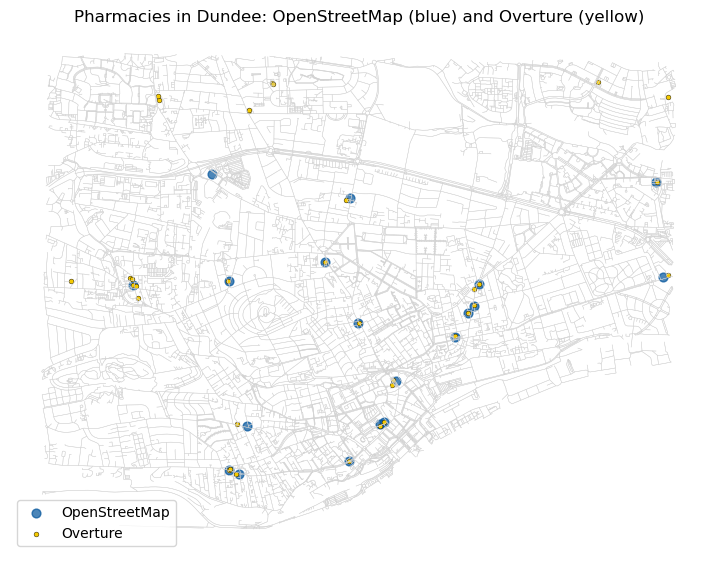

In [71]:
fig, ax = plt.subplots(figsize=(9, 9))
edges.plot(ax=ax, color="lightgrey", linewidth=0.3)
pharmacy.plot(ax=ax, color="#00539B", markersize=40, label="OpenStreetMap", alpha=0.7)
overture_pharmacy.plot(ax=ax, color="#F4C900", markersize=12, label="Overture", edgecolor="black", linewidth=0.3)
ax.legend(loc="lower left")
ax.set_title("Pharmacies in Dundee: OpenStreetMap (blue) and Overture (yellow)")
ax.set_axis_off()
plt.show()

Overture lists 34 pharmacies in Dundee, whereas OSM lists 19. After plotting this on a map, it is clear that a lot of these pharmacies match between OSM and Overture, but there are a few others recognised as pharmacies by Overture in the North, and a cluster of pharmacies compared to only one OSM pharmacy in the West.

### Challenge 4

In [81]:
# lab code (removed code relevant to bikes)

PERTH = (56.3960, -3.4370)       # Originally this was Glasgow West End, but to make it easier to find a location, we have moved the study area to Perth.
AREA = 1500                        # metres: the neighbourhood area we study, also to reflect the 15-minute neighbourhood concept (15 minutes walking = 1200 metres, 20 minutes cycling = 5000 metres)
WALK_LIMIT = 800                  # changed value to 800, 10 min walking

SERVICES = {
    "School":           {"amenity": "school"},
    "Food shop":        {"shop": ["supermarket", "convenience", "greengrocer"]},
    "Healthcare":       {"amenity": ["doctors", "clinic", "pharmacy", "hospital"]},
    "Park":             {"leisure": "park"},
    "Public transport": {"highway": "bus_stop", "railway": "station"},
}

In [75]:
G_walk = ox.load_graphml("data/perth_walk.graphml")
G_walk = ox.project_graph(G_walk, to_crs="EPSG:27700").to_undirected()

In [76]:
walk_nodes, walk_edges = ox.graph_to_gdfs(G_walk)

residential = gpd.read_file("data/perth_residential.gpkg").to_crs("EPSG:27700")
residential_area = unary_union(list(residential.geometry))

centre = gpd.GeoSeries.from_xy([PERTH[1]], [PERTH[0]], crs="EPSG:4326").to_crs("EPSG:27700")
neighbourhood = centre.buffer(AREA).iloc[0]

homes = walk_nodes[walk_nodes.within(residential_area) & walk_nodes.within(neighbourhood)].copy()

In [82]:
services = gpd.read_file("data/perth_services.gpkg").to_crs("EPSG:27700")

for name in SERVICES:
    points = services[services["service"] == name].geometry

    walk_targets = ox.distance.nearest_nodes(G_walk, points.x, points.y)
    walk_dist = nx.multi_source_dijkstra_path_length(G_walk, set(walk_targets), weight="length")

    homes[name + " walk (m)"] = [walk_dist.get(n) for n in homes.index]
    #print(f"{name:<17} {len(points):>5} found")

In [83]:
results = pd.DataFrame(index=list(SERVICES))
results["% homes within 15-min walk"] = [(homes[s + " walk (m)"] <= WALK_LIMIT).mean() * 100 for s in SERVICES]
#results.round(0)

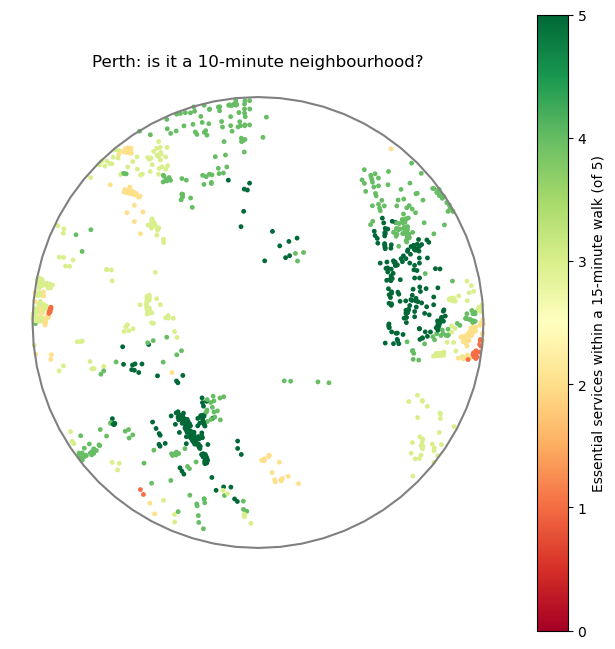

30% of residential junctions reach all 5 services on foot


In [85]:
homes["services_walk"] = sum((homes[s + " walk (m)"] <= WALK_LIMIT).astype(int) for s in SERVICES)

ax = homes.plot(column="services_walk", cmap="RdYlGn", vmin=0, vmax=5, markersize=6, legend=True,
                figsize=(8, 8), legend_kwds={"label": "Essential services within a 15-minute walk (of 5)"})
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="grey")
ax.set_title("Perth: is it a 10-minute neighbourhood?")
ax.set_axis_off()
plt.show()

print(f"{(homes['services_walk'] == 5).mean():.0%} of residential junctions reach all 5 services on foot")

After changing the WALK_LIMIT to 800, around 10 minutes, only 30% of homes still reach all 5 services. There are even some homes where only 1 essential service is accessible within 10 minutes, and most can access 3 or 4.

### Challenge 5

In [92]:
def isochrone(G, start_node, metres):
    reachable = nx.ego_graph(G, start_node, radius=metres, distance="length")
    streets = ox.graph_to_gdfs(reachable, nodes=False)
    return unary_union(list(streets.buffer(50)))

In [94]:
home = ox.distance.nearest_nodes(G_walk, centre.x.iloc[0], centre.y.iloc[0])   # the junction nearest the centre

#fig, ax = plt.subplots(figsize=(9, 9))
#walk_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
#for minutes, colour in [(15, "#cfe0f0"), (10, "#7fb0dd"), (5, "#00539B")]:
    #shape = isochrone(G_walk, home, minutes * WALK_SPEED)
    #gpd.GeoSeries([shape], crs="EPSG:27700").plot(ax=ax, color=colour, alpha=0.8)

#iso15 = isochrone(G_walk, home, 15 * WALK_SPEED)
#inside = services[services.within(iso15)]
#for name, colour in zip(SERVICES, ["#608738", "#C22A22", "#785596", "#2a9d8f", "#F4C900"]):
    #inside[inside["service"] == name].plot(ax=ax, color=colour, markersize=25, label=name, edgecolor="black", linewidth=0.3)

#ax.legend(loc="lower left")
#ax.set_xlim(iso15.bounds[0] - 300, iso15.bounds[2] + 300)
#ax.set_ylim(iso15.bounds[1] - 300, iso15.bounds[3] + 300)
#ax.set_title("5, 10 and 15-minute walk from one home, with the services inside")
#ax.set_axis_off()
#plt.show()

#print(inside["service"].value_counts())

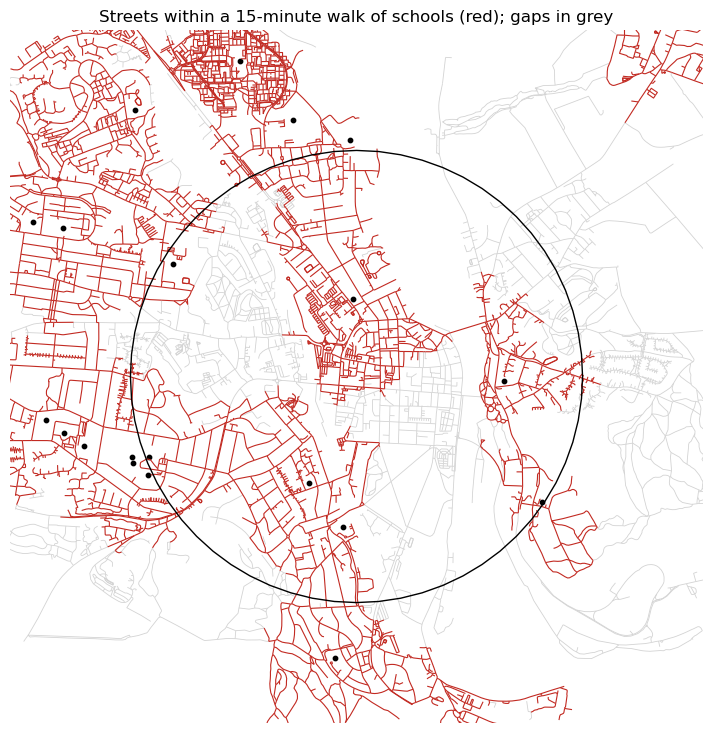

In [95]:
school = services[services["service"] == "School"]
school_nodes = set(ox.distance.nearest_nodes(G_walk, school.geometry.x, school.geometry.y))
dist_to_school = nx.multi_source_dijkstra_path_length(G_walk, school_nodes, cutoff=WALK_LIMIT, weight="length")

walk_edges = walk_edges.reset_index()
walk_edges["covered"] = walk_edges["u"].isin(set(dist_to_school)) & walk_edges["v"].isin(set(dist_to_school))

fig, ax = plt.subplots(figsize=(9, 9))
walk_edges[~walk_edges["covered"]].plot(ax=ax, color="lightgrey", linewidth=0.6)
walk_edges[walk_edges["covered"]].plot(ax=ax, color="#C22A22", linewidth=0.8)
school.plot(ax=ax, color="black", markersize=10)
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="black", linewidth=1)
west, south, east, north = neighbourhood.buffer(WALK_LIMIT).bounds      # zoom to the neighbourhood
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_title("Streets within a 15-minute walk of schools (red); gaps in grey")
ax.set_axis_off()
plt.show()

There are large grey gaps in the centre and West side of the circle, as there are dense, built-up areas but no school within a walkable distance. There are also large gaps in the East, as almost all roads are grey. However, it is hard to tell if these gaps are concerning as the map does not show whether these grey roads are residential.

### Challenge 6.1

In [ ]:
CITY = "Girona, Spain"  # or "Leuven, Belgium", "Popayán, Colombia", your home town...
CATCHMENT = 1200
G_city = ox.graph_from_place(CITY, network_type="walk")
G_city = ox.project_graph(G_city).to_undirected()
crs = G_city.graph["crs"]
parks = ox.features_from_place(CITY, tags={"leisure": "park"}).to_crs(crs)
parks = parks[parks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks["area_m2"] = parks.area
buildings = ox.features_from_place(CITY, tags={"building": True}).to_crs(crs)

In [ ]:
parks["node"] = ox.distance.nearest_nodes(G_city, parks.representative_point().x, parks.representative_point().y)
buildings["node"] = ox.distance.nearest_nodes(G_city, buildings.representative_point().x, buildings.representative_point().y)

demand = buildings["node"].value_counts()        # junction -> number of buildings
#demand.head()

In [ ]:
reach = {}          # which junctions can walk to each park
ratio = {}          # park area divided by the buildings that can reach it

for park_id, park in parks.iterrows():
    nearby = nx.single_source_dijkstra_path_length(G_city, park["node"], cutoff=CATCHMENT, weight="length")
    buildings_nearby = sum(demand.get(node, 0) for node in nearby)
    reach[park_id] = nearby
    ratio[park_id] = park["area_m2"] / buildings_nearby if buildings_nearby > 0 else 0

parks["m2_per_building"] = pd.Series(ratio)
#parks.sort_values("m2_per_building", ascending=False)[["name", "area_m2", "m2_per_building"]].head(10).round(0)

In [ ]:
city_nodes, city_edges = ox.graph_to_gdfs(G_city)
park_access = {node: 0.0 for node in G_city.nodes}

for park_id, nearby in reach.items():
    for node in nearby:
        park_access[node] += ratio[park_id]

city_nodes["park_access"] = pd.Series(park_access)

homes_city = city_nodes[city_nodes.index.isin(demand.index)]       # junctions that have buildings
#homes_city["park_access"].describe().round(0)

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks.plot(ax=ax, color="#a8d5a2")
homes_city.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,
                                           markersize=8, legend=True,
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})
ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

print(f"{(homes_city['park_access'] == 0).mean():.0%} of homes have no park within a 15-minute walk")

When copying my code into a separate notebook for submission, I got a timeout error and so wasn't able to verify this was working as it did last time I ran this code. As far as i'm aware, this code should function and work provided the api request doesn't time out. I have included a picture of my map below.

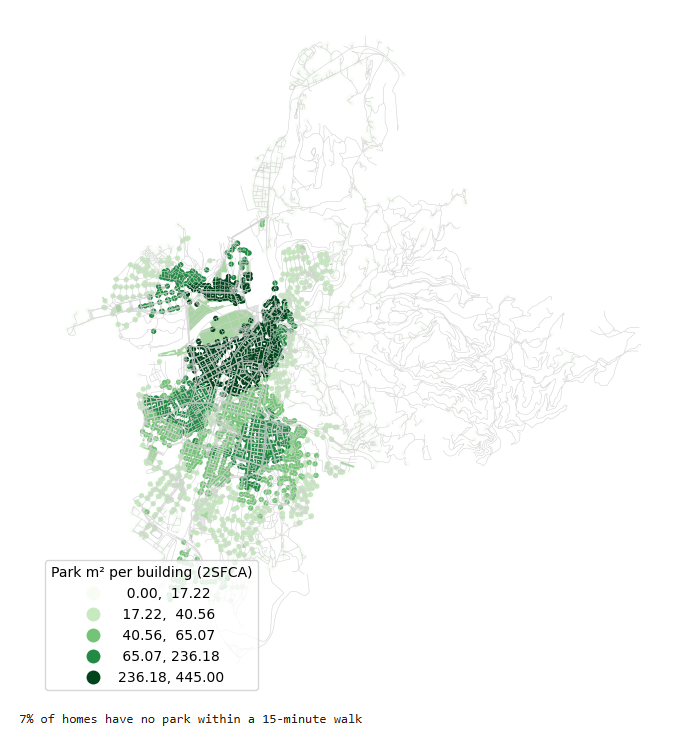